<a href="https://colab.research.google.com/github/dhiyaulhaqq21/pm-turi4-clustering/blob/main/PM_P9_MuhammadDhiyaulHaque_2488010041.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
df = pd.read_csv('data_segmentasi_pelanggan.csv')
X_scaled = StandardScaler().fit_transform(df)


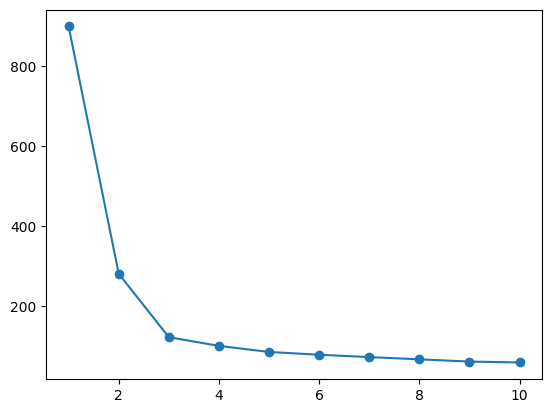

In [3]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()


In [4]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())


cluster
1    100
2    100
0    100
Name: count, dtype: int64


In [5]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))


0.5743185408180522


In [6]:
profil = df.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
print(profil)   # beri nama tiap cluster berdasarkan profil


         usia  pendapatan  skor_belanja
cluster                                
0        24.6        40.2          85.2
1        60.1       110.6          26.8
2        45.7        68.5          48.8


# D Latihan Mandiri #
6. Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.

In [7]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())

from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))


cluster
2    100
1     62
0     60
4     42
3     36
Name: count, dtype: int64
0.43708876745616143


Silhouette score untuk K=3 lebih tinggi dibandingkan K=5. Hal ini menunjukkan bahwa membagi data menjadi 3 klaster jauh lebih optimal dan kepadatan antar anggota klaster lebih baik dibandingkan memaksakan pembagian menjadi 5 klaster.


7. Jalankan K-Means tanpa scaling (K=3); bandingkan silhouette-nya. Apa kesimpulannya?

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Ambil kolom fitur asli tanpa scaling
X_asli = df[['usia', 'pendapatan', 'skor_belanja']]

# 2. Inisialisasi dan jalankan K-Means (K=3) langsung pada data asli
kmeans_unscaled = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster_unscaled'] = kmeans_unscaled.fit_predict(X_asli)

# 3. Evaluasi silhouette score
score_unscaled = silhouette_score(X_asli, df['cluster_unscaled'])
print(f"Silhouette Score tanpa scaling (K=3): {score_unscaled}")

Silhouette Score tanpa scaling (K=3): 0.5496270182897706


Tanpa scaling, silhouette score sedikit menurun, namun masalah utamanya bukan sekadar angka. Karena algoritma K-Means menggunakan perhitungan jarak Euclidean, fitur dengan rentang nilai yang lebih besar (seperti "pendapatan") akan mendominasi perhitungan jarak. Akibatnya, klaster yang terbentuk menjadi bias dan hanya dipengaruhi oleh satu atau dua fitur besar, mengabaikan fitur dengan rentang nilai kecil. Oleh karena itu, melakukan scaling wajib dilakukan pada K-Means.

8. Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y).

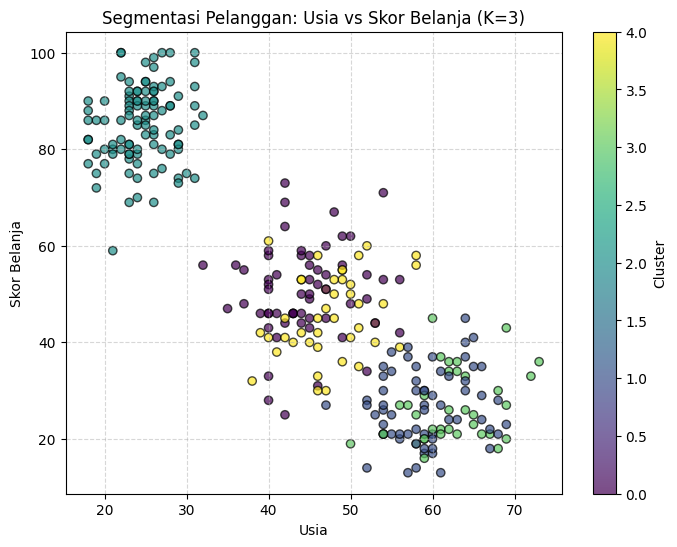

In [9]:
import matplotlib.pyplot as plt

# Pastikan df['cluster'] saat ini berisi hasil K-Means dengan K=3 (menggunakan data yang di-scale)
plt.figure(figsize=(8, 6))

# Membuat scatter plot, x = usia, y = skor belanja, c = pewarnaan berdasarkan cluster
scatter = plt.scatter(df['usia'], df['skor_belanja'], c=df['cluster'], cmap='viridis', edgecolors='k', alpha=0.7)

plt.title('Segmentasi Pelanggan: Usia vs Skor Belanja (K=3)')
plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.colorbar(scatter, label='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)

# Tampilkan grafik
plt.show()

Dari grafik di atas, karakteristik 3 kelompok pelanggan terlihat sangat terpisah:

*   Klaster Ungu: Pelanggan usia muda dengan skor belanja sangat tinggi.
*   Klaster Kuning: Pelanggan usia paruh baya dengan skor belanja menengah.
*   Klaster Hijau: Pelanggan usia tua dengan skor belanja rendah.






# E Refleksi #
1. Bagaimana K-Means menemukan kelompok tanpa label?

    k-means dapat menemukan kelompok tanpa label dengan cara membagi data ke K kelompok. yang mana K ini sudah kita tentukan dari awal. Pengelompokannya ditentukan oleh jarak data ke  nilai centroid (rata-rata karakteristik data).
2.	Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?

    karena nilai Inersia atau Within-Cluster Sum of Squares (WCSS) mengalami penurunan taraf efisiensi paling drastis (titik balik marginal utility) pada jumlah klaster tersebut

3. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?

    Scaling sangat penting dalam algoritma K-Means karena untuk mengukur kemiripan antar-data. Jika data tidak di-scale, fitur yang memiliki rentang angka paling besar akan mendominasi selisih kuadrat dalam rumus jarak.